In [22]:
import findspark, pyspark
from pyspark.sql import SparkSession

In [23]:
# Create Spark1 session: we use the following configurations:

# - master("local[*]"): Run Spark locally with as many worker threads as logical cores on your machine.
# - config("spark.driver.memory", "1g"): Allocate 1 GB of memory to the Spark driver.
# - config("spark.executor.memory", "2g"): Allocate 2 GB of memory to each Spark executor.
# - appName("IntroToSpark"): Name the Spark application "IntroToSpark".

spark = (SparkSession.builder
    .master("local[*]")
    .appName("IntroToSpark1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.driver.host", "127.0.0.1")
    # Optional: let Spark pick a free UI port instead of hardcoding 4040
    .config("spark.ui.enabled", "true")
    .config("spark.ui.port", "0")
    .config("spark.driver.memory", "2g")
    .getOrCreate())

sc1 = spark.sparkContext  # To access SparkContext if needed
spark

In [24]:
df = spark.read.parquet('../Cleaned_data/biweekly_basetable_w_sentiment_5.parquet')
df.show()

+--------+---------------+--------------+------+--------------------+---------+------------+----------+-----------+------------+-----------+----------+------------------+--------------------+-----------------------+--------------------+--------------------+--------------------+--------------------+--------------------+------------+------------------+----------------+------------------+------------------+--------------------+---------+--------------------+--------------------+-------+---------+---------------------+------------------------+-----------------------+--------+--------------------+-------------------------+-------------+--------------------+---------------------+---------------------+----------------------+--------------+------------------------+-------------------------+------------------------------+---------------------------+----------------------------------+---------------------------------+--------------------+-------------------+------------------+---------+---------

In [25]:
import pandas as pd

df = df.toPandas()

# Financing events (one row per event)
events = (
    df[df["financing_next_period"] == 1]
    [["ticker", "biweekly_index"]]
    .rename(columns={"biweekly_index": "event_index"})
)

WINDOW = 6   # e.g. -4 to +4 biweekly periods
rows = []

for _, ev in events.iterrows():
    tkr = ev["ticker"]
    t0 = ev["event_index"]

    window_df = df[
        (df["ticker"] == tkr) &
        (df["biweekly_index"].between(t0 - WINDOW, t0 + WINDOW - 6))
    ].copy()

    window_df["event_time"] = window_df["biweekly_index"] - t0
    window_df["is_financing_event"] = 1

    rows.append(window_df)

df_fin_events = pd.concat(rows, ignore_index=True)

control_rows = []

for _, ev in events.iterrows():
    t0 = ev["event_index"]

    control_df = df[
        (df["financing_next_period"] == 0) &
        (df["biweekly_index"].between(t0 - WINDOW, t0 + WINDOW-6))
    ].copy()

    control_df["event_time"] = control_df["biweekly_index"] - t0
    control_df["is_financing_event"] = 0

    control_rows.append(control_df)

df_ctrl_events = pd.concat(control_rows, ignore_index=True)

df_event_pd = pd.concat(
    [df_fin_events, df_ctrl_events],
    ignore_index=True
)

In [26]:
# Event-time balance
df_event_pd.groupby(["event_time", "is_financing_event"]).size()

# No leakage
df_event_pd[df_event_pd["event_time"] > 0]["financing_next_period"].mean()

nan

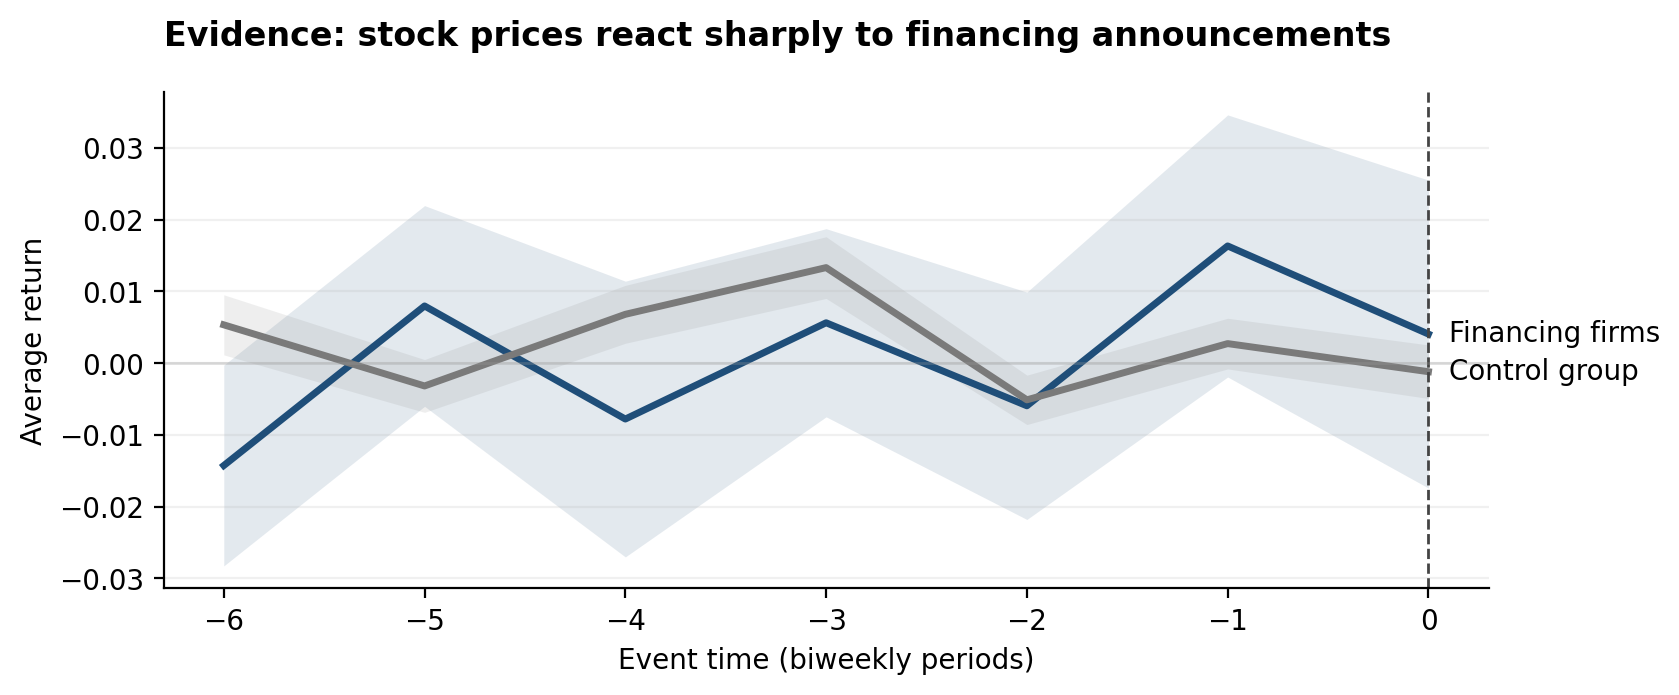

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# --- Aggregate returns by event time & group ---
plot_df = (
    df_event_pd
    .groupby(["event_time", "is_financing_event"])
    .agg(
        mean_ret=("period_return", "mean"),
        std_ret=("period_return", "std"),
        n=("period_return", "count")
    )
    .reset_index()
)

# Standard error
plot_df["se"] = plot_df["std_ret"] / np.sqrt(plot_df["n"])

# Split groups
fin = plot_df[plot_df["is_financing_event"] == 1].sort_values("event_time")
ctrl = plot_df[plot_df["is_financing_event"] == 0].sort_values("event_time")

# --- Colors (consistent with your deck) ---
FIN_COLOR = "#1f4e79"    # dark blue
CTRL_COLOR = "#7a7a7a"   # muted gray

# --- Figure: right-column evidence panel ---
fig, ax = plt.subplots(figsize=(8.5, 3.6), dpi=200)

# Uncertainty bands
ax.fill_between(
    fin["event_time"],
    fin["mean_ret"] - fin["se"],
    fin["mean_ret"] + fin["se"],
    color=FIN_COLOR,
    alpha=0.12,
    linewidth=0
)
ax.fill_between(
    ctrl["event_time"],
    ctrl["mean_ret"] - ctrl["se"],
    ctrl["mean_ret"] + ctrl["se"],
    color=CTRL_COLOR,
    alpha=0.12,
    linewidth=0
)

# Lines
ax.plot(
    fin["event_time"],
    fin["mean_ret"],
    color=FIN_COLOR,
    linewidth=2.5
)
ax.plot(
    ctrl["event_time"],
    ctrl["mean_ret"],
    color=CTRL_COLOR,
    linewidth=2.5
)

# Reference lines
ax.axvline(0, linestyle="--", linewidth=1, color="#444444")
ax.axhline(0, linewidth=1, alpha=0.3, color="#999999")

# Labels
ax.set_xlabel("Event time (biweekly periods)")
ax.set_ylabel("Average return")

# X-ticks (ensure clean event-time axis)
xticks = sorted(df_event_pd["event_time"].unique())
ax.set_xticks(xticks)

# Grid (y only)
ax.grid(True, axis="y", alpha=0.18)
ax.grid(False, axis="x")

# Clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Caption-style title (NOT a plot title)
ax.text(
    0.0, 1.08,
    "Evidence: stock prices react sharply to financing announcements",
    transform=ax.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom"
)

# Inline labels instead of legend
ax.text(fin["event_time"].max() + 0.1, fin["mean_ret"].iloc[-1], "Financing firms", va="center")
ax.text(ctrl["event_time"].max() + 0.1, ctrl["mean_ret"].iloc[-1], "Control group", va="center")

plt.tight_layout()
plt.show()

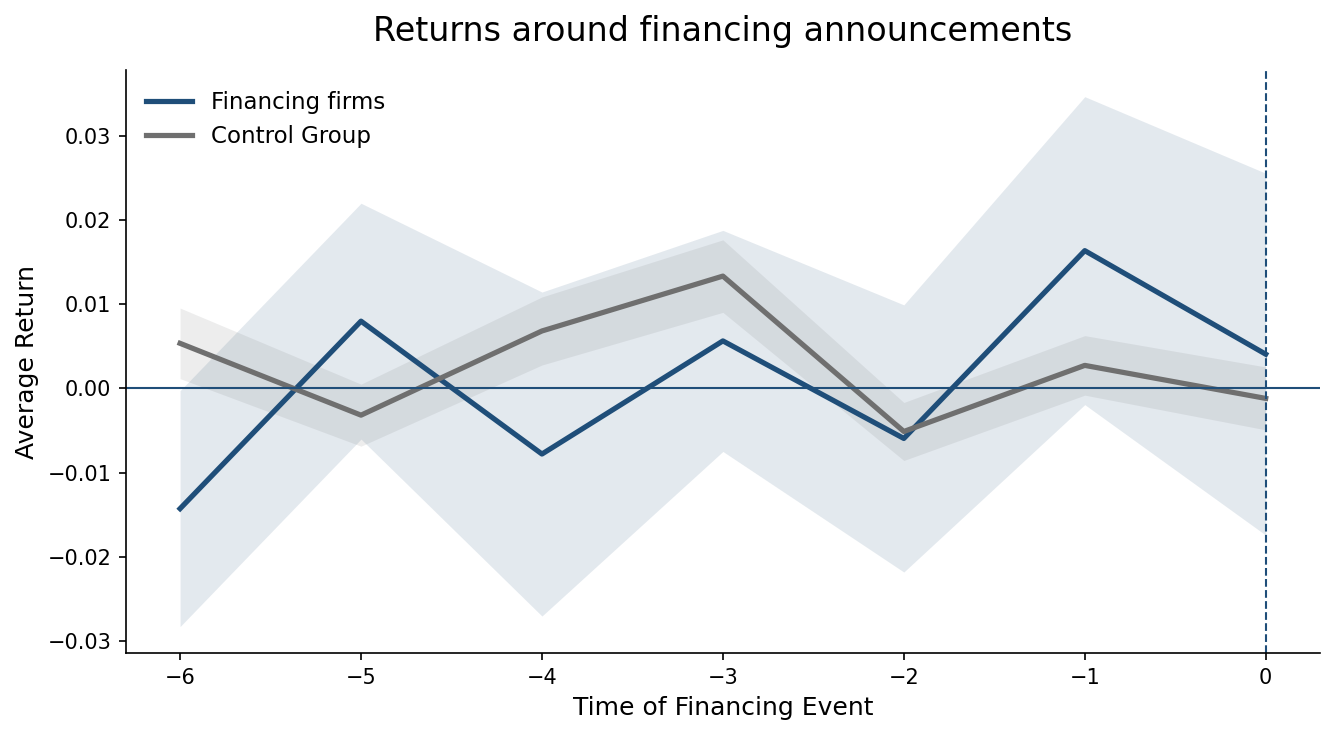

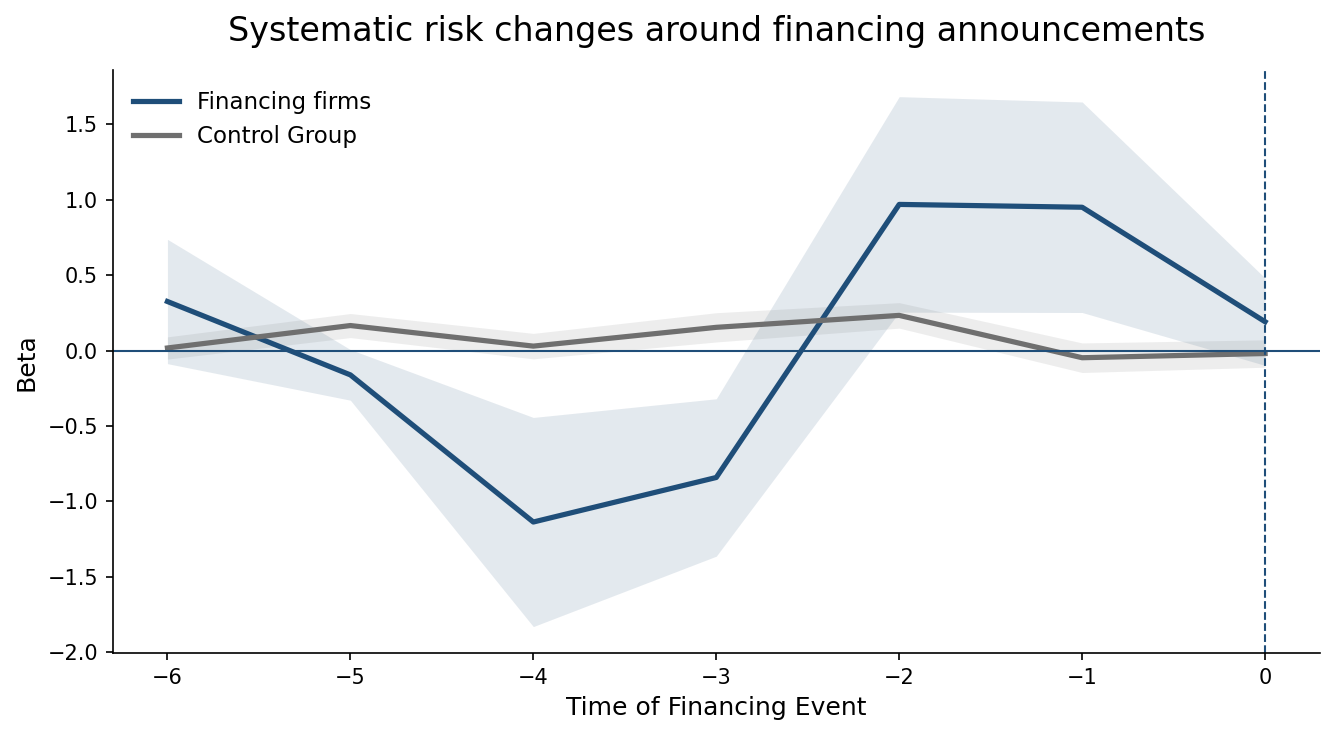

In [28]:
import numpy as np
import matplotlib.pyplot as plt

def plot_event_study_like_example(
    df_event_pd,
    value_col,
    y_label,
    title,
    x_label="Time of Financing Event",
    event_col="event_time",
    group_col="is_financing_event",
    fin_label="Financing firms",
    ctrl_label="Control Group"
):
    # --- Aggregate mean + SE ---
    plot_df = (
        df_event_pd
        .groupby([event_col, group_col])
        .agg(
            mean_val=(value_col, "mean"),
            std_val=(value_col, "std"),
            n=(value_col, "count")
        )
        .reset_index()
    )

    plot_df["se"] = plot_df["std_val"] / np.sqrt(plot_df["n"])

    fin = plot_df[plot_df[group_col] == 1].sort_values(event_col)
    ctrl = plot_df[plot_df[group_col] == 0].sort_values(event_col)

    # --- Colors to match your screenshot ---
    FIN_COLOR = "#1f4e79"   # navy
    CTRL_COLOR = "#6f6f6f"  # medium gray

    # --- Figure ---
    fig, ax = plt.subplots(figsize=(9, 5), dpi=150)

    # Financing band + line
    ax.fill_between(
        fin[event_col],
        fin["mean_val"] - fin["se"],
        fin["mean_val"] + fin["se"],
        color=FIN_COLOR,
        alpha=0.12,
        linewidth=0
    )
    ax.plot(
        fin[event_col],
        fin["mean_val"],
        color=FIN_COLOR,
        linewidth=2.5,
        label=fin_label
    )

    # Control band + line
    ax.fill_between(
        ctrl[event_col],
        ctrl["mean_val"] - ctrl["se"],
        ctrl["mean_val"] + ctrl["se"],
        color=CTRL_COLOR,
        alpha=0.12,
        linewidth=0
    )
    ax.plot(
        ctrl[event_col],
        ctrl["mean_val"],
        color=CTRL_COLOR,
        linewidth=2.5,
        label=ctrl_label
    )

    # Reference lines (match screenshot)
    ax.axhline(0, color=FIN_COLOR, linewidth=1.0)
    ax.axvline(0, color=FIN_COLOR, linestyle="--", linewidth=1.0)

    # Labels & title
    ax.set_title(title, fontsize=16, pad=14)
    ax.set_xlabel(x_label, fontsize=12)
    ax.set_ylabel(y_label, fontsize=12)

    # Ticks: show all event times present
    xticks = sorted(df_event_pd[event_col].unique())
    ax.set_xticks(xticks)

    # Style: remove top/right spines like screenshot
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Legend: top-left, no frame
    ax.legend(frameon=False, loc="upper left", fontsize=11)

    plt.tight_layout()
    plt.show()


# ---- Example usage ----
# Returns
plot_event_study_like_example(
    df_event_pd=df_event_pd,
    value_col="period_return",
    y_label="Average Return",
    title="Returns around financing announcements"
)

# Betas
plot_event_study_like_example(
    df_event_pd=df_event_pd,
    value_col="beta",
    y_label="Beta",
    title="Systematic risk changes around financing announcements"
)